# Training a Transformer with PyTorch

A Transformer is a sequence-to-sequence encoder-decoder model similar to the RNN model.
Unlike RNN, Transformer is parallelizable. The temporal relation between the words in a sentence/ sequence is encoded by self attention layers.
Transformers make no assumptions about the temporal/spatial relationships across the data, it is learnt.


As explained in the [Google AI Blog post](https://ai.googleblog.com/2017/08/transformer-novel-neural-network.html):

> Neural networks for machine translation typically contain an encoder reading the input sentence and generating a representation of it. A decoder then generates the output sentence word by word while consulting the representation generated by the encoder. The Transformer starts by generating initial representations, or embeddings, for each input word. Then, using self-attention, it aggregates information from all of the other words, generating a new representation per word informed by the entire context. This step is then repeated multiple times in parallel for all words, successively generating new representations.

The goal of this tutorial is to break it down into easy to understand parts. In this tutorial we will:

- To build our Transformer model, we’ll follow these steps:

1. Import necessary libraries and modules.
2. Define the basic building blocks: Multi-Head Attention, Position-wise Feed-Forward Networks, Positional Encoding.
3. Build the Encoder and Decoder layers.
4. Combine Encoder and Decoder layers to create the complete Transformer model.
5. Prepare sample data.
6. Train the model.


<table>
<tr>
  <th>The RNN+Attention model</a></th>
  <th>A 1-layer transformer</th>
</tr>
<tr>
  <td>
   <img width=411 src="https://www.tensorflow.org/images/tutorials/transformer/RNN+attention-words.png"/>
  </td>
  <td>
   <img width=400 src="https://www.tensorflow.org/images/tutorials/transformer/Transformer-1layer-words.png"/>
  </td>
</tr>
</table>

<table>
<td>
<tr>
  <th>Cross Attention: each query sees the whole context.</th>
  <th colspan=1>Self attention</th>
</tr>
<tr>
  <td>
   <img width=430 src="https://www.tensorflow.org/images/tutorials/transformer/CrossAttention-new.png"/>
  </td>
  <td>
   <img width=330 src="https://www.tensorflow.org/images/tutorials/transformer/SelfAttention-new-full.png"/>
  </td>
</tr>
</table>

## Setup

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
import math
import copy

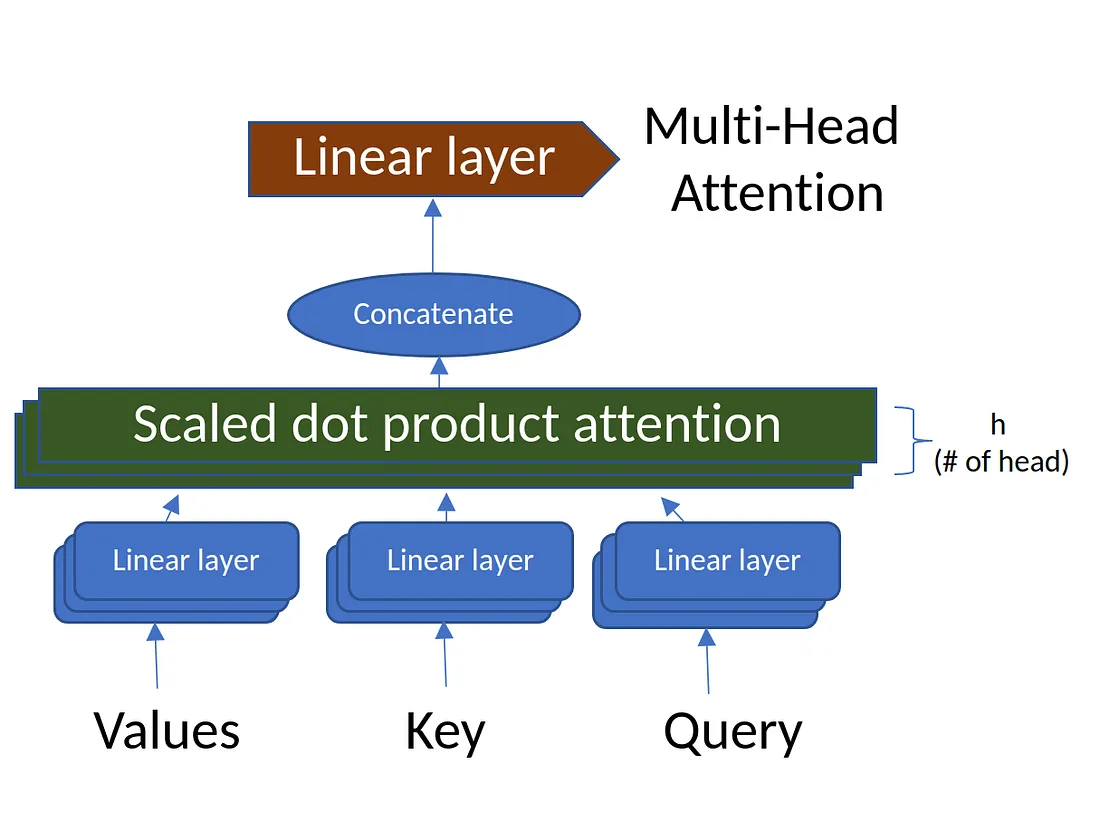

The Multi-Head Attention mechanism computes the attention between each pair of positions in a sequence. It consists of multiple “attention heads” that capture different aspects of the input sequence.

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def scaled_dot_product_attention(self, Q, K, V, mask=None):
        attn_scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            attn_scores = attn_scores.masked_fill(mask == 0, -1e9)
        attn_probs = torch.softmax(attn_scores, dim=-1)
        output = torch.matmul(attn_probs, V)
        return output

#Before: (batch_size, seq_length, num_heads, d_k)
#After: (batch_size, num_heads, seq_length, d_k)
    def split_heads(self, x):
        batch_size, seq_length, d_model = x.size()
        return x.view(batch_size, seq_length, self.num_heads, self.d_k).transpose(1, 2)

    def combine_heads(self, x):
        batch_size, _, seq_length, d_k = x.size()
        return x.transpose(1, 2).contiguous().view(batch_size, seq_length, self.d_model)

    def forward(self, Q, K, V, mask=None):
        Q = self.split_heads(self.W_q(Q))
        K = self.split_heads(self.W_k(K))
        V = self.split_heads(self.W_v(V))

        attn_output = self.scaled_dot_product_attention(Q, K, V, mask)
        output = self.W_o(self.combine_heads(attn_output))
        return output

#Position-wise Feed-Forward Networks

The PositionWiseFeedForward class extends PyTorch’s nn.Module and implements a position-wise feed-forward network. The class initializes with two linear transformation layers and a ReLU activation function. The forward method applies these transformations and activation function sequentially to compute the output. This process enables the model to consider the position of input elements while making predictions.

In [ ]:
class PositionWiseFeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super(PositionWiseFeedForward, self).__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))

#Positional Encoding

Positional Encoding is used to inject the position information of each token in the input sequence. It uses sine and cosine functions of different frequencies to generate the positional encoding.

The original paper uses the following formula for calculating the positional encoding:

$$\Large{PE_{(pos, 2i)} = \sin(pos / 10000^{2i / d_{model}})} $$
$$\Large{PE_{(pos, 2i+1)} = \cos(pos / 10000^{2i / d_{model}})} $$

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_seq_length):
        super(PositionalEncoding, self).__init__()

        pe = torch.zeros(max_seq_length, d_model)
        position = torch.arange(0, max_seq_length, dtype=torch.float).unsqueeze(1)
        #log-exp trick: a^(-b) = exp(-b*ln(a))
        #Here a=10000, b=2i/d_model
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        #To make positional encodings part of the model's state but not update during training
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

#Encoder Layer

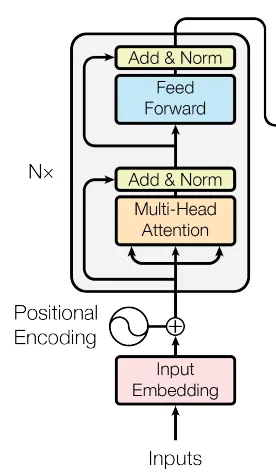

An Encoder layer consists of a Multi-Head Attention layer, a Position-wise Feed-Forward layer, and two Layer Normalization layers.

In [ ]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout):
        super(EncoderLayer, self).__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionWiseFeedForward(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask):
        attn_output = self.self_attn(x, x, x, mask)
        x = self.norm1(x + self.dropout(attn_output))
        ff_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ff_output))
        return x

#Decoder Layer

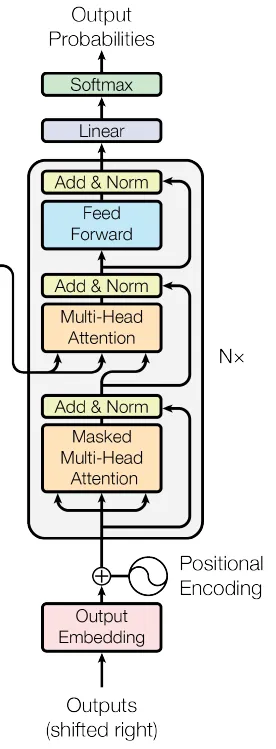

A Decoder layer consists of two Multi-Head Attention layers, a Position-wise Feed-Forward layer, and three Layer Normalization layers.

In [ ]:
class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout):
        super(DecoderLayer, self).__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads)
        self.cross_attn = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionWiseFeedForward(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, enc_output, src_mask, tgt_mask):
        attn_output = self.self_attn(x, x, x, tgt_mask)
        x = self.norm1(x + self.dropout(attn_output))
        attn_output = self.cross_attn(x, enc_output, enc_output, src_mask)
        x = self.norm2(x + self.dropout(attn_output))
        ff_output = self.feed_forward(x)
        x = self.norm3(x + self.dropout(ff_output))
        return x

The forward method computes the decoder layer output by performing the following steps:

1. Calculate the masked self-attention output and add it to the input tensor, followed by dropout and layer normalization.

2. Compute the cross-attention output between the decoder and encoder outputs, and add it to the normalized masked self-attention output, followed by dropout and layer normalization.

3. Calculate the position-wise feed-forward output and combine it with the normalized cross-attention output, followed by dropout and layer normalization.

4. Return the processed tensor.

These operations enable the decoder to generate target sequences based on the input and the encoder output.

#Transformer Model

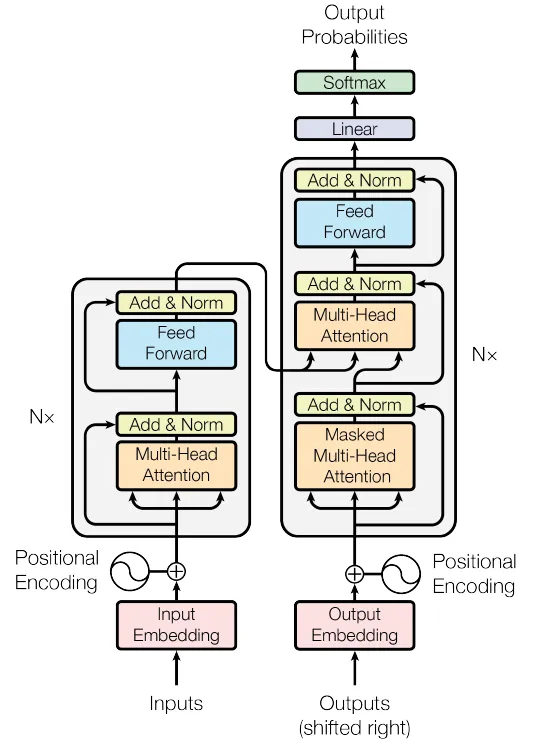

The forward method computes the Transformer model’s output through the following steps:

1. Generate source and target masks using the generate_mask method.

2. Compute source and target embeddings, and apply positional encoding and dropout.

3. Process the source sequence through encoder layers, updating the enc_output tensor.

4. Process the target sequence through decoder layers, using enc_output and masks, and updating the dec_output tensor.

5. Apply the linear projection layer to the decoder output, obtaining output logits.

These steps enable the Transformer model to process input sequences and generate output sequences based on the combined functionality of its components.



In [ ]:
class Transformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model, num_heads, num_layers, d_ff, max_seq_length, dropout):
        super(Transformer, self).__init__()
        self.encoder_embedding = nn.Embedding(src_vocab_size, d_model)
        self.decoder_embedding = nn.Embedding(tgt_vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_seq_length)

        self.encoder_layers = nn.ModuleList([EncoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.decoder_layers = nn.ModuleList([DecoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])

        self.fc = nn.Linear(d_model, tgt_vocab_size)
        self.dropout = nn.Dropout(dropout)

    def generate_mask(self, src, tgt):
        src_mask = (src != 0).unsqueeze(1).unsqueeze(2)
        tgt_mask = (tgt != 0).unsqueeze(1).unsqueeze(3)
        seq_length = tgt.size(1)
        nopeak_mask = (1 - torch.triu(torch.ones(1, seq_length, seq_length), diagonal=1)).bool()
        tgt_mask = tgt_mask & nopeak_mask
        return src_mask, tgt_mask

    def forward(self, src, tgt):
        src_mask, tgt_mask = self.generate_mask(src, tgt)
        src_embedded = self.dropout(self.positional_encoding(self.encoder_embedding(src)))
        tgt_embedded = self.dropout(self.positional_encoding(self.decoder_embedding(tgt)))

        enc_output = src_embedded
        for enc_layer in self.encoder_layers:
            enc_output = enc_layer(enc_output, src_mask)

        dec_output = tgt_embedded
        for dec_layer in self.decoder_layers:
            dec_output = dec_layer(dec_output, enc_output, src_mask, tgt_mask)

        output = self.fc(dec_output)
        return output

#Preparing Sample Data

In this example, we will create a toy dataset for demonstration purposes. In practice, you would use a larger dataset, preprocess the text, and create vocabulary mappings for source and target languages.

In [ ]:
src_vocab_size = 5000
tgt_vocab_size = 5000
d_model = 512
num_heads = 8
num_layers = 6
d_ff = 2048 #dimension of feed-forward layer
max_seq_length = 100
dropout = 0.1

transformer = Transformer(src_vocab_size, tgt_vocab_size, d_model, num_heads, num_layers, d_ff, max_seq_length, dropout)

# Generate random sample data
src_data = torch.randint(1, src_vocab_size, (64, max_seq_length))  # (batch_size, seq_length)
tgt_data = torch.randint(1, tgt_vocab_size, (64, max_seq_length))  # (batch_size, seq_length)

#Training the Model

In [ ]:
criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = optim.Adam(transformer.parameters(), lr=0.0001, betas=(0.9, 0.98), eps=1e-9)

transformer.train()

for epoch in range(100):
    optimizer.zero_grad()
    output = transformer(src_data, tgt_data[:, :-1])
    loss = criterion(output.contiguous().view(-1, tgt_vocab_size), tgt_data[:, 1:].contiguous().view(-1))
    loss.backward()
    optimizer.step()
    print(f"Epoch: {epoch+1}, Loss: {loss.item()}")

Epoch: 1, Loss: 8.6756010055542
Epoch: 2, Loss: 8.545374870300293
Epoch: 3, Loss: 8.476218223571777
Epoch: 4, Loss: 8.416267395019531
Epoch: 5, Loss: 8.35931396484375
Epoch: 6, Loss: 8.282073974609375
Epoch: 7, Loss: 8.199085235595703
Epoch: 8, Loss: 8.121031761169434
Epoch: 9, Loss: 8.040597915649414
Epoch: 10, Loss: 7.953232288360596
Epoch: 11, Loss: 7.86962890625
Epoch: 12, Loss: 7.791081428527832
Epoch: 13, Loss: 7.70359468460083
Epoch: 14, Loss: 7.621032238006592
Epoch: 15, Loss: 7.540018081665039
Epoch: 16, Loss: 7.458738803863525
Epoch: 17, Loss: 7.370782852172852
Epoch: 18, Loss: 7.289713382720947
Epoch: 19, Loss: 7.214544773101807
Epoch: 20, Loss: 7.139204978942871
Epoch: 21, Loss: 7.050459861755371
Epoch: 22, Loss: 6.975365161895752
Epoch: 23, Loss: 6.898815631866455
Epoch: 24, Loss: 6.826595306396484
Epoch: 25, Loss: 6.753725528717041
Epoch: 26, Loss: 6.672556400299072
Epoch: 27, Loss: 6.599162578582764
Epoch: 28, Loss: 6.528015613555908
Epoch: 29, Loss: 6.457740306854248
Ep

# Inference

The following steps are used for inference:

* Encode the input sequence using a Embedder. This is the encoder input.
* The decoder input is initialized to the `[START]` token.
* Calculate the padding masks and the look ahead masks.
* The `decoder` then outputs the predictions by looking at the `encoder output` and its own output (self-attention).
* Concatenate the predicted token to the decoder input and pass it to the decoder.
* In this approach, the decoder predicts the next token based on the previous tokens it predicted.



### Create Dummy Vocabulary

In [ ]:
import torchtext
from collections import defaultdict

# For simplicity, create dummy vocabularies. In a real scenario, these would be built from your dataset.

# Create a dummy source vocabulary (word to index)
src_word_to_idx = defaultdict(lambda: 3) # Default to an 'unknown' token index
src_idx_to_word = defaultdict(lambda: '<unk>')

# Assign special tokens
src_word_to_idx['<pad>'] = 0
src_idx_to_word[0] = '<pad>'
src_word_to_idx['<eos>'] = 1
src_idx_to_word[1] = '<eos>'
src_word_to_idx['<sos>'] = 2
src_idx_to_word[2] = '<sos>'

# Add some example words
words = ['hello', 'world', 'how', 'are', 'you', 'i', 'am', 'fine', 'thank', 'goodbye']
for i, word in enumerate(words):
    src_word_to_idx[word] = i + 4 # Start from index 4 after special tokens
    src_idx_to_word[i + 4] = word

# Ensure src_vocab_size matches what was used in the Transformer model
# If your actual vocab size is larger, you'd need to adjust the dummy vocab creation.
# For this demo, let's assume the dummy vocab size is sufficient or we adjust src_vocab_size if needed.
current_src_vocab_size = len(src_word_to_idx)

# Create a dummy target vocabulary (word to index)
tgt_word_to_idx = defaultdict(lambda: 3) # Default to an 'unknown' token index
tgt_idx_to_word = defaultdict(lambda: '<unk>')

# Assign special tokens
tgt_word_to_idx['<pad>'] = 0
tgt_idx_to_word[0] = '<pad>'
tgt_word_to_idx['<eos>'] = 1
tgt_idx_to_word[1] = '<eos>'
tgt_word_to_idx['<sos>'] = 2
tgt_idx_to_word[2] = '<sos>'

# Add some example words (can be different from source)
tgt_words = ['greetings', 'universe', 'what', 'is', 'up', 'we', 'are', 'doing', 'well', 'bye']
for i, word in enumerate(tgt_words):
    tgt_word_to_idx[word] = i + 4 # Start from index 4 after special tokens
    tgt_idx_to_word[i + 4] = word

current_tgt_vocab_size = len(tgt_word_to_idx)

print(f"Source Vocabulary Size (dummy): {current_src_vocab_size}")
print(f"Target Vocabulary Size (dummy): {current_tgt_vocab_size}")

# You might need to re-initialize the transformer if these dummy vocab sizes are significantly different
# from the original src_vocab_size and tgt_vocab_size used for training, especially if a smaller vocab
# was used initially and your dummy vocab is now larger. For this demo, we'll proceed assuming it's fine.

### Translate Function for Inference

In [ ]:
def translate(model, src_sentence, src_word_to_idx, tgt_idx_to_word, max_seq_length, device='cpu'):
    model.eval() # Set the model to evaluation mode

    # Convert source sentence to token IDs and add SOS/EOS tokens
    src_tokens = [src_word_to_idx['<sos>']] + [src_word_to_idx.get(word, src_word_to_idx['<unk>']) for word in src_sentence.split()] + [src_word_to_idx['<eos>']]

    # Pad source tokens to max_seq_length
    src_padded = src_tokens + [src_word_to_idx['<pad>']] * (max_seq_length - len(src_tokens))
    src = torch.LongTensor(src_padded).unsqueeze(0).to(device) # Add batch dimension

    # Initialize target sequence with <sos> token
    tgt = torch.LongTensor([[tgt_word_to_idx['<sos>']]]).to(device)

    for _ in range(max_seq_length - 1): # Iterate up to max_seq_length - 1 times (to allow for EOS)
        # Get model output
        with torch.no_grad():
            output = model(src, tgt)

        # Predict the next token (take the last token's prediction)
        pred_token_idx = output[:, -1, :].argmax(dim=-1)

        # Append the predicted token to the target sequence
        tgt = torch.cat([tgt, pred_token_idx.unsqueeze(0)], dim=1)

        # If the predicted token is <eos>, stop decoding
        if pred_token_idx.item() == tgt_word_to_idx['<eos>']:
            break

    # Convert target token IDs back to words
    translated_tokens = [tgt_idx_to_word[idx.item()] for idx in tgt.squeeze(0)]

    # Remove <sos> and <eos> tokens from the result
    if '<sos>' in translated_tokens: translated_tokens.remove('<sos>')
    if '<eos>' in translated_tokens: translated_tokens.remove('<eos>')

    return ' '.join(translated_tokens)


### Inference Example

In [ ]:
# Example Usage:

# Assuming 'transformer' is your trained model from the previous steps
# Move model to device if using GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
transformer.to(device)

# Dummy source sentence
source_sentence = "hello world how are you"

# Translate the sentence
translated_sentence = translate(transformer, source_sentence, src_word_to_idx, tgt_idx_to_word, max_seq_length, device)

print(f"Source: {source_sentence}")
print(f"Translated: {translated_sentence}")

# Another example
source_sentence_2 = "i am fine thank you"
translated_sentence_2 = translate(transformer, source_sentence_2, src_word_to_idx, tgt_idx_to_word, max_seq_length, device)

print(f"\nSource: {source_sentence_2}")
print(f"Translated: {translated_sentence_2}")

## Visualization of learned attention weights generated from a Transfomer trained to translate Portugese in English:

<img src="https://www.tensorflow.org/images/tutorials/transformer/attention_map_portuguese.png" alt="Attention heatmap">